# Evaluación de Aya-101 con las 15 historias sintéticas

Corre las dos estrategias de extracción sobre los 15 casos de `ejemplos_hc/` y compara cada valor con `esperados.json`. Calcula exactitud, precisión, recall y F1 con intervalos de confianza del 95 %, la tasa de JSON válido, los tipos de error, el tiempo de cada corrida y la memoria de la GPU.

Las historias son sintéticas: las cifras describen el comportamiento del modelo en estos 15 casos, no en historias reales de una IPS.

Antes de empezar, en **Entorno de ejecución → Cambiar tipo de entorno de ejecución**, elige **T4 GPU**. Para clonar el repo privado hace falta el secret `GITHUB_TOKEN` (ver `notebooks/despliegue_colab.ipynb`, celda 2).

Al terminar, descarga el notebook con sus salidas (**Archivo → Descargar → .ipynb**) para guardarlo en el repo. Descarga también los archivos de la carpeta `resultados/`.

## 1. Preparar el entorno

In [2]:
# Sirve en Colab y en una copia local del repo
import os
import subprocess
import sys

REPO_URL = "https://github.com/joan999/aya101_historias_clinicas.git"
RAMA = "main"   # rama que se clona
EN_COLAB = "google.colab" in sys.modules


def token_github():
    """Lee el token de los Secrets de Colab. Si no está, devuelve None."""
    try:
        from google.colab import userdata
        return userdata.get("GITHUB_TOKEN")
    except Exception as error:
        print("Sin token de GitHub:", type(error).__name__)
        return None


def git(*args, token=None, cwd=None):
    """Corre git y tapa el token en lo que imprime."""
    resultado = subprocess.run(["git", *args], cwd=cwd, capture_output=True, text=True,
                               env={**os.environ, "GIT_TERMINAL_PROMPT": "0"})
    texto = (resultado.stdout + resultado.stderr).strip()
    if token:
        texto = texto.replace(token, "***")
    if texto:
        print(texto)
    if resultado.returncode != 0:
        raise RuntimeError("git falló: revisa el secret GITHUB_TOKEN y que el token tenga acceso al repo")


if EN_COLAB:
    token = token_github()
    url = REPO_URL.replace("https://", f"https://x-access-token:{token}@") if token else REPO_URL
    carpeta = "/content/" + REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if os.path.exists(carpeta):
        git("pull", "-q", url, RAMA, token=token, cwd=carpeta)
    else:
        git("clone", "-q", "--branch", RAMA, url, carpeta, token=token)
        git("remote", "set-url", "origin", REPO_URL, cwd=carpeta)
    os.chdir(carpeta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers==5.24.0",
                    "accelerate==1.16.0", "bitsandbytes==0.50.2", "pymupdf==2.1"], check=True)
elif not os.path.exists("src") and os.path.exists("../src"):
    os.chdir("..")   # fuera de Colab se usa la carpeta del repo
sys.path.insert(0, os.getcwd())
print("Carpeta del proyecto:", os.getcwd())

Carpeta del proyecto: /content/aya101_historias_clinicas


## 2. Cargar Aya-101

In [3]:
import time

import torch

from src.config import MODELO_ID
from src.modelo import cargar_modelo

inicio = time.time()
tokenizador, modelo = cargar_modelo(MODELO_ID)
print(f"Modelo: {MODELO_ID} | descarga y carga: {time.time() - inicio:.0f} s")
if torch.cuda.is_available():
    usada = torch.cuda.memory_allocated()
    total = torch.cuda.get_device_properties(0).total_memory
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM del modelo cargado: {usada / 1e9:.2f} GB ({usada / 1024**3:.2f} GiB) de {total / 1e9:.1f} GB")

config.json:   0%|          | 0.00/836 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/833 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors.index.json: reconstructing file:   0%|          |  0.00B / 50.6kB            

model.safetensors.index.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

Modelo: CohereLabs/aya-101 | descarga y carga: 1521 s
GPU: Tesla T4
VRAM del modelo cargado: 13.11 GB (12.21 GiB) de 15.6 GB


## 3. Correr los 15 casos

Con la estrategia de una pregunta por variable, las 10 preguntas de un caso van en un solo lote. Con la estrategia JSON se hace una sola pregunta por caso. Cada casilla (historia × variable) queda en una de cuatro categorías:

- **correcto**: igual al esperado (números con tolerancia de 1e-6), incluido «no registrado» cuando el dato no está;
- **valor distinto**: el dato estaba y el modelo dio otro;
- **omitido**: el dato estaba y el modelo no lo dio;
- **inventado**: el dato no estaba y el modelo dio uno.

In [4]:
import json
from pathlib import Path

import pandas as pd

from src.config import MAX_TOKENS_JSON, MAX_TOKENS_VARIABLE, TIPOS, VARIABLES
from src.inferencia import inferir
from src.metricas import clasificar, es_json_valido
from src.posproceso import leer_json, normalizar
from src.prompts import prompt_json, prompt_por_variable

POR_VARIABLE, JSON_ = "Una pregunta por variable", "Un solo prompt con JSON"
ESTRATEGIAS = [POR_VARIABLE, JSON_]

esperados = json.loads(Path("ejemplos_hc/esperados.json").read_text(encoding="utf-8"))
filas, tiempos = [], []
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

for caso, valores in esperados.items():
    historia = Path("ejemplos_hc", caso).read_text(encoding="utf-8").strip()

    inicio = time.time()
    prompts = [prompt_por_variable(historia, pregunta, tipo) for _, tipo, pregunta in VARIABLES]
    salida = inferir(tokenizador, modelo, prompts, historia, MAX_TOKENS_VARIABLE)
    tiempos.append({"caso": caso, "estrategia": POR_VARIABLE, "segundos": time.time() - inicio, "json_valido": None})
    for (clave, tipo, _), res in zip(VARIABLES, salida):
        valor = normalizar(res["texto"], tipo)
        filas.append({"caso": caso, "estrategia": POR_VARIABLE, "variable": clave, "tipo": tipo, "respuesta": res["texto"],
                      "valor": valor, "esperado": valores[clave], "resultado": clasificar(valor, valores[clave])})

    inicio = time.time()
    res = inferir(tokenizador, modelo, [prompt_json(historia)], historia, MAX_TOKENS_JSON)[0]
    tiempos.append({"caso": caso, "estrategia": JSON_, "segundos": time.time() - inicio, "json_valido": es_json_valido(res["texto"])})
    leidos = leer_json(res["texto"])
    for clave, tipo in TIPOS.items():
        filas.append({"caso": caso, "estrategia": JSON_, "variable": clave, "tipo": tipo, "respuesta": res["texto"],
                      "valor": leidos[clave], "esperado": valores[clave], "resultado": clasificar(leidos[clave], valores[clave])})
    print(caso, "listo")

resultados = pd.DataFrame(filas)
resultados["correcto"] = resultados["resultado"] == "correcto"
tiempos = pd.DataFrame(tiempos)
Path("resultados").mkdir(exist_ok=True)
resultados.to_csv("resultados/evaluacion_detalle.csv", index=False)
tiempos.to_csv("resultados/evaluacion_tiempos.csv", index=False)
print("Guardado en resultados/:", len(resultados), "casillas y", len(tiempos), "corridas")

caso_1.txt listo
caso_2.txt listo
caso_3.txt listo
caso_4.txt listo
caso_5.txt listo
caso_6.txt listo
caso_7.txt listo
caso_8.txt listo
caso_9.txt listo
caso_10.txt listo
caso_11.txt listo
caso_12.txt listo
caso_13.txt listo
caso_14.txt listo
caso_15.txt listo
Guardado en resultados/: 300 casillas y 30 corridas


## 4. Exactitud

Porcentaje de casillas iguales al valor esperado. El intervalo del 95 % es el de Wilson para una proporción: con 150 casillas por estrategia, si los intervalos de las dos estrategias se cruzan, la diferencia puede ser azar.

In [5]:
from src.metricas import intervalo_wilson


def con_intervalo(tabla):
    """Agrega exactitud e intervalo de Wilson a una tabla con columnas aciertos y total."""
    tabla["exactitud"] = (tabla["aciertos"] / tabla["total"]).round(3)
    limites = [intervalo_wilson(a, t) for a, t in zip(tabla["aciertos"], tabla["total"])]
    tabla["IC 95 %"] = [f"{bajo:.3f} – {alto:.3f}" for bajo, alto in limites]
    return tabla


print("Exactitud global:")
display(con_intervalo(resultados.groupby("estrategia")["correcto"].agg(aciertos="sum", total="size")))

print("Exactitud por tipo de variable (4 Sí/No y 6 numéricas):")
nombres_tipo = {"si_no": "Sí/No", "numero": "numérica"}
display(con_intervalo(resultados.assign(tipo=resultados["tipo"].map(nombres_tipo))
                      .groupby(["estrategia", "tipo"])["correcto"].agg(aciertos="sum", total="size")))

print("Tipo de resultado por estrategia:")
display(resultados.pivot_table(index="resultado", columns="estrategia", values="caso", aggfunc="count", fill_value=0))

por_variable = resultados.pivot_table(index="variable", columns="estrategia", values="correcto", aggfunc="mean").reindex(list(TIPOS))
print("Exactitud por variable (15 casos cada una):")
display(por_variable.round(2))

orden_casos = sorted(esperados, key=lambda nombre: int(nombre[5:-4]))
print("Aciertos por caso (de 10):")
display(resultados.pivot_table(index="caso", columns="estrategia", values="correcto", aggfunc="sum").reindex(orden_casos))

Exactitud global:


,aciertos,total,exactitud,IC 95 %
estrategia,,,,
Un solo prompt con JSON,81,150,0.540,0.460 – 0.618
Una pregunta por variable,104,150,0.693,0.615 – 0.762


Exactitud por tipo de variable (4 Sí/No y 6 numéricas):


aciertos  total  exactitud        IC 95 %
estrategia                tipo                                               
Un solo prompt con JSON   Sí/No           34     60      0.567  0.441 – 0.684
                          numérica        47     90      0.522  0.420 – 0.622
Una pregunta por variable Sí/No           34     60      0.567  0.441 – 0.684
                          numérica        70     90      0.778  0.682 – 0.851

Tipo de resultado por estrategia:


estrategia,Un solo prompt con JSON,Una pregunta por variable
resultado,,
correcto,81,104
inventado,2,0
omitido,65,22
valor distinto,2,24


Exactitud por variable (15 casos cada una):


estrategia,Un solo prompt con JSON,Una pregunta por variable
variable,,
diagnostico_hta,0.60,0.80
diagnostico_dm,0.60,0.47
diagnostico_erc,0.60,0.33
tas_mmhg,0.60,1.00
tad_mmhg,0.13,0.40
peso_kg,0.67,1.00
talla_m,0.67,0.93
creatinina_mg_dl,0.60,1.00
hba1c_pct,0.47,0.33


Aciertos por caso (de 10):


estrategia,Un solo prompt con JSON,Una pregunta por variable
caso,,
caso_1.txt,0,8
caso_2.txt,8,7
caso_3.txt,0,6
caso_4.txt,0,6
caso_5.txt,9,5
caso_6.txt,9,8
caso_7.txt,9,7
caso_8.txt,9,9
caso_9.txt,0,4


## 5. Precisión, recall y F1

Se cuentan las casillas así: valor correcto = VP; valor equivocado = FP y FN; valor inventado = FP; valor omitido = FN. Las casillas sin dato que el modelo deja vacías no entran.

- **Precisión**: de lo que llena el modelo, cuánto está bien. Es la que más importa para el reporte a la CAC.
- **Recall**: de lo que está en la historia, cuánto encuentra.
- **F1**: las dos en un solo número.

El intervalo del 95 % del F1 sale de 2000 remuestreos de las 15 historias (bootstrap con semilla 42). Se remuestrean historias completas porque las 10 casillas de una historia no son independientes.

In [6]:
from src.metricas import intervalo_bootstrap_f1, precision_recall_f1

filas_prf = []
for estrategia in ESTRATEGIAS:
    propias = [f for f in filas if f["estrategia"] == estrategia]
    m = precision_recall_f1([(f["valor"], f["esperado"]) for f in propias])
    por_caso = {}
    for f in propias:
        por_caso.setdefault(f["caso"], []).append((f["valor"], f["esperado"]))
    bajo, alto = intervalo_bootstrap_f1(por_caso, repeticiones=2000, semilla=42)
    filas_prf.append({"estrategia": estrategia, **m, "IC 95 % del F1": f"{bajo:.3f} – {alto:.3f}"})
prf = pd.DataFrame(filas_prf).set_index("estrategia")
display(prf.round(3))

f1_por_variable = pd.DataFrame({
    estrategia: {clave: precision_recall_f1([(f["valor"], f["esperado"]) for f in filas
                                             if f["estrategia"] == estrategia and f["variable"] == clave])["F1"]
                 for clave in TIPOS}
    for estrategia in ESTRATEGIAS
})
print("F1 por variable:")
display(f1_por_variable.round(2))

,VP,FP,FN,precisión,recall,F1,IC 95 % del F1
estrategia,,,,,,,
Una pregunta por variable,98,24,46,0.803,0.681,0.737,0.674 – 0.794
Un solo prompt con JSON,77,4,67,0.951,0.535,0.684,0.463 – 0.846


F1 por variable:


,Una pregunta por variable,Un solo prompt con JSON
diagnostico_hta,0.86,0.75
diagnostico_dm,0.64,0.75
diagnostico_erc,0.48,0.75
tas_mmhg,1.00,0.75
tad_mmhg,0.40,0.24
peso_kg,1.00,0.78
talla_m,0.93,0.78
creatinina_mg_dl,1.00,0.73
hba1c_pct,0.17,0.60
usa_ieca_ara2,0.74,0.58


## 6. ¿La estrategia JSON devuelve JSON?

Porcentaje de las 15 salidas de la estrategia JSON que se pueden leer como JSON sin el lector de respaldo de `src/posproceso.py`.

In [7]:
validos = tiempos.loc[tiempos["estrategia"] == JSON_, "json_valido"].astype(bool)
bajo, alto = intervalo_wilson(int(validos.sum()), len(validos))
print(f"JSON válido: {int(validos.sum())} de {len(validos)} ({validos.mean():.0%}); IC 95 %: {bajo:.2f} – {alto:.2f}")

JSON válido: 0 de 15 (0%); IC 95 %: 0.00 – 0.20


## 7. Gráficos

F1 y exactitud por variable para las dos estrategias. Los números exactos están en las tablas de arriba.

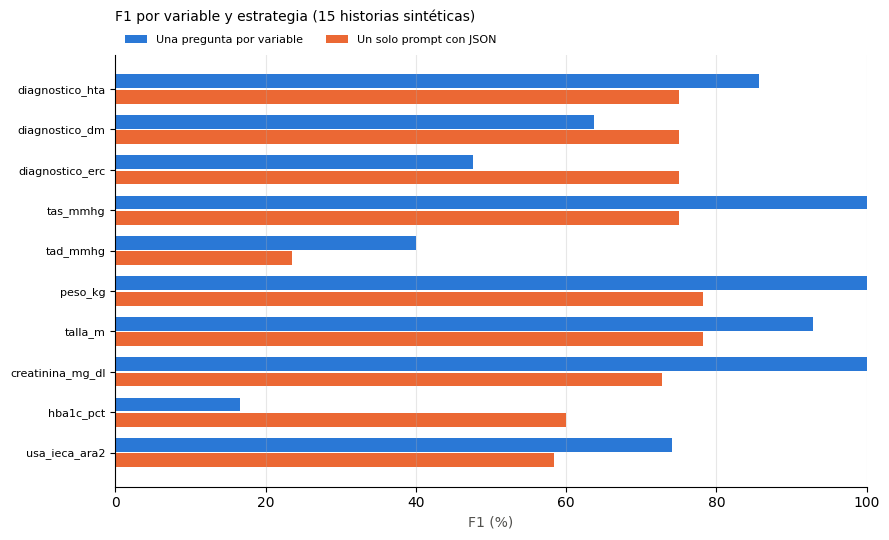

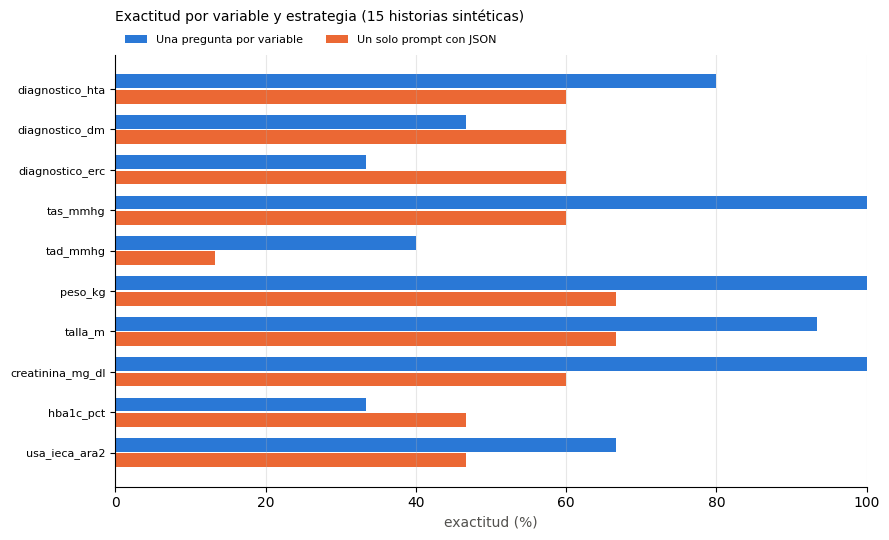

In [8]:
import matplotlib.pyplot as plt

from src.graficos import COLOR_ESTRATEGIA, TEXTO_SECUNDARIO


def barras_por_variable(tabla, titulo, eje_x, archivo):
    variables = list(TIPOS)
    figura, eje = plt.subplots(figsize=(9, 5.5))
    alto = 0.38
    for k, estrategia in enumerate(ESTRATEGIAS):
        posiciones = [i + (k - 0.5) * alto for i in range(len(variables))]
        eje.barh(posiciones, tabla[estrategia].reindex(variables).values * 100, height=alto - 0.04,
                 color=COLOR_ESTRATEGIA[estrategia], label=estrategia)
    eje.set_yticks(range(len(variables)), variables, fontsize=8)
    eje.invert_yaxis()
    eje.set_xlim(0, 100)
    eje.set_xlabel(eje_x, color=TEXTO_SECUNDARIO)
    eje.set_title(titulo, fontsize=10, loc="left", pad=24)
    eje.grid(axis="x", alpha=0.3)
    eje.spines[["top", "right"]].set_visible(False)
    eje.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=8)
    figura.tight_layout()
    figura.savefig(f"resultados/{archivo}", dpi=150)
    plt.show()


barras_por_variable(f1_por_variable, "F1 por variable y estrategia (15 historias sintéticas)", "F1 (%)", "f1_por_variable.png")
barras_por_variable(por_variable, "Exactitud por variable y estrategia (15 historias sintéticas)", "exactitud (%)", "exactitud_por_variable.png")

## 8. Tiempo y memoria

In [9]:
display(tiempos.groupby("estrategia")["segundos"].describe()[["mean", "50%", "min", "max"]].round(1)
        .rename(columns={"mean": "media", "50%": "mediana", "min": "mínimo", "max": "máximo"}))
if torch.cuda.is_available():
    print(f"VRAM máxima durante la evaluación: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

,media,mediana,mínimo,máximo
estrategia,,,,
Un solo prompt con JSON,15.0,10.8,9.5,22.2
Una pregunta por variable,25.2,25.0,22.3,30.5


VRAM máxima durante la evaluación: 14.63 GB


## 9. Dónde se equivoca

Todas las casillas que no coinciden, con la respuesta que dio el modelo (recortada a 90 caracteres).

In [10]:
fallos = resultados[~resultados["correcto"]].copy()
fallos["respuesta"] = fallos["respuesta"].str.slice(0, 90)
pd.set_option("display.max_rows", 400)
display(fallos[["caso", "estrategia", "variable", "respuesta", "valor", "esperado", "resultado"]])

,caso,estrategia,variable,respuesta,valor,esperado,resultado
2,caso_1.txt,Una pregunta por variable,diagnostico_erc,No registrado.,None,No,omitido
8,caso_1.txt,Una pregunta por variable,hba1c_pct,El valor de hemoglobina glicosilada (HbA1c) en...,1.0,7.4,valor distinto
10,caso_1.txt,Un solo prompt con JSON,diagnostico_hta,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí, sí. Sí, sí...",None,Sí,omitido
11,caso_1.txt,Un solo prompt con JSON,diagnostico_dm,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí, sí. Sí, sí...",None,Sí,omitido
12,caso_1.txt,Un solo prompt con JSON,diagnostico_erc,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí, sí. Sí, sí...",None,No,omitido
13,caso_1.txt,Un solo prompt con JSON,tas_mmhg,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí, sí. Sí, sí...",None,138,omitido
14,caso_1.txt,Un solo prompt con JSON,tad_mmhg,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí, sí. Sí, sí...",None,84,omitido
15,caso_1.txt,Un solo prompt con JSON,peso_kg,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí, sí. Sí, sí...",None,76,omitido
16,caso_1.txt,Un solo prompt con JSON,talla_m,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí, sí. Sí, sí...",None,1.68,omitido
17,caso_1.txt,Un solo prompt con JSON,creatinina_mg_dl,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí, sí. Sí, sí...",None,1.15,omitido


## 10. Guardar los resultados

In [11]:
prf.to_csv("resultados/precision_recall_f1.csv")
if EN_COLAB:
    from google.colab import files
    for archivo in ["evaluacion_detalle.csv", "evaluacion_tiempos.csv", "precision_recall_f1.csv",
                    "f1_por_variable.png", "exactitud_por_variable.png"]:
        files.download(f"resultados/{archivo}")
else:
    print("Resultados en la carpeta resultados/")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>